# Day 19 | Control a Local Model's Replies

**KGP Talkie**

Compare output limits, temperature, context space, and a reusable Modelfile.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

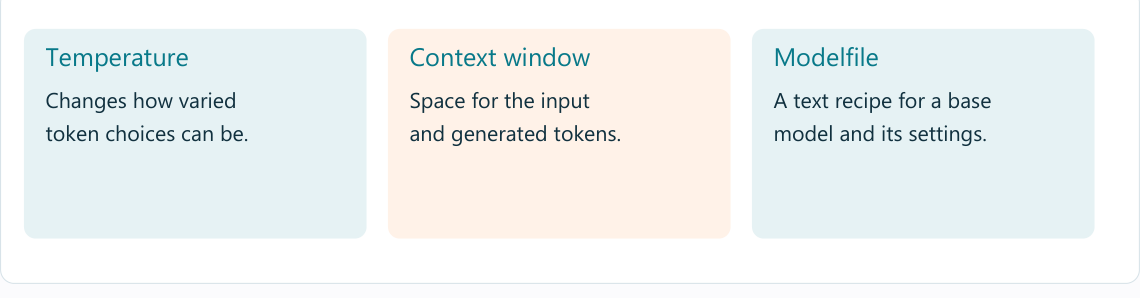

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 96-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=96, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [7]:
prompt = "Write two short lines about the sun."

In [8]:
print(llm.invoke(prompt).content)

The sun is a massive ball of hot, glowing gas that serves as the center of our solar system. Its intense heat and light have a profound impact on the Earth's climate and ecosystems.


A different temperature tests varied choices; 0.8 is a comparison value, not a best setting for every task.

In [9]:
varied = ChatOllama(model=MODEL, temperature=0.8, num_predict=96, client_kwargs={"timeout": 180})

In [10]:
print(varied.invoke(prompt).content)

The sun is a massive ball of hot, glowing gas that makes up about 99.8% of our solar system's mass. Its surface temperature can reach as high as 5,500 degrees Celsius, making it one of the most extreme environments in the universe.


A tiny output cap deliberately shows a reply that may end too soon.

In [11]:
short = ChatOllama(model=MODEL, temperature=0, num_predict=12, client_kwargs={"timeout": 180})

In [12]:
print(short.invoke("Explain Python lists in five points.").content)

Here are five key points about Python lists:

1. **


In [13]:
print((ASSETS / "Modelfile").read_text())

FROM llama3.2
PARAMETER temperature 0
PARAMETER num_predict 128
SYSTEM "You teach beginners. Use short sentences and define new terms."



To create the recipe in the terminal from this day folder: `ollama create kgp-classroom -f assets/Modelfile`. Then try `ollama run kgp-classroom`. This adds a local model name; it does not train new weights.

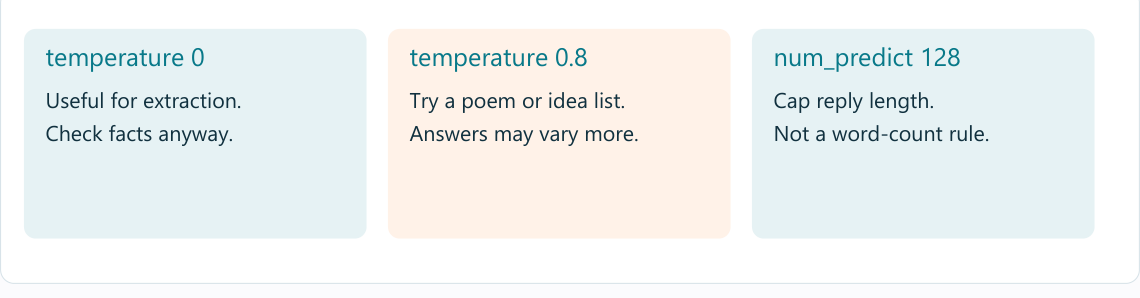

## Try a fresh input

Read the supplied Modelfile and change only the teaching rule. Create a new model name in the terminal if you want to try it.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/ollama-setup-guide).